# Time-of-Day Analysis: Spring DST and Fatal Traffic Crashes

## Research Question

Does the relationship between the spring daylight saving time (DST) transition and fatal traffic crashes differ by time of day?

We extend the group's overall spring DST analysis by dividing fatal crashes into four six-hour categories: overnight, morning, afternoon, and evening.

We use a 21-day window before and after each spring DST transition from 2000 through 2024, excluding transition Sunday. We first examine descriptive differences and then fit a Poisson regression with an interaction between DST status and time of day.

### Load Packages and Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import calendar

import statsmodels.api as sm
import statsmodels.formula.api as smf

from pathlib import Path
from IPython.display import display

data_path = Path("../data/fars_2000_2024_clean.parquet")

fars = pd.read_parquet(data_path)

print("Number of records:", len(fars))
print("Years:", fars["year"].min(), "to", fars["year"].max())
print("Columns:", fars.columns.tolist())

Number of records: 881056
Years: 2000 to 2024
Columns: ['state', 'county', 'month', 'day', 'hour', 'minute', 've_forms', 'persons', 'peds', 'nhs', 'route', 'sp_jur', 'harm_ev', 'man_coll', 'rel_road', 'lgt_cond', 'weather', 'not_hour', 'not_min', 'arr_hour', 'arr_min', 'hosp_hr', 'hosp_mn', 'sch_bus', 'cf1', 'cf2', 'cf3', 'fatals', 'day_week', 'drunk_dr', 'st_case', 'city', 'milept', 'year', 'tway_id', 'rail', 'latitude', 'longitud', 'tway_id2', 've_total', 'weather1', 'weather2', 'wrk_zone', 'reljct1', 'reljct2', 'typ_int', 'pvh_invl', 'pernotmvit', 'permvit', 'statename', 'dayname', 'monthname', 'day_weekname', 'hourname', 'minutename', 'nhsname', 'routename', 'rur_urb', 'rur_urbname', 'func_sys', 'func_sysname', 'rd_owner', 'rd_ownername', 'mileptname', 'latitudename', 'longitudname', 'sp_jurname', 'harm_evname', 'man_collname', 'reljct1name', 'reljct2name', 'typ_intname', 'wrk_zonename', 'rel_roadname', 'lgt_condname', 'weather1name', 'weather2name', 'weathername', 'sch_busname', '

### Define the spring DST transition dates

In [7]:
# Determine the spring DST transition for each year
def spring_dst_date(year):
    if year < 2007:
        month = 4
        sunday_number = 0  # First Sunday in April
    else:
        month = 3
        sunday_number = 1  # Second Sunday in March

    sundays = [
        week[calendar.SUNDAY]
        for week in calendar.monthcalendar(year, month)
        if week[calendar.SUNDAY] != 0]
    return pd.Timestamp(
        year=year,
        month=month,
        day=sundays[sunday_number])

dst_dates = pd.DataFrame({"year": range(2000, 2025)})

dst_dates["spring_dst"] = dst_dates["year"].apply(spring_dst_date)

display(dst_dates)

,year,spring_dst
0,2000,2000-04-02
1,2001,2001-04-01
2,2002,2002-04-07
3,2003,2003-04-06
4,2004,2004-04-04
5,2005,2005-04-03
6,2006,2006-04-02
7,2007,2007-03-11
8,2008,2008-03-09
9,2009,2009-03-08


### Prepare the spring DST comparison

In [8]:
# Define the four time-of-day categories
periods = ["Overnight", "Morning", "Afternoon", "Evening"]

# Exclude the same states as the main statistical analysis
excluded_states = [4, 15, 18, 72]

crashes = fars[
    ~fars["state"].isin(excluded_states)
].copy()

# Check how many records have unknown crash times
crashes["hour"] = pd.to_numeric(crashes["hour"], errors="coerce")

missing_hours = (~crashes["hour"].between(0, 23)).sum()

print("Records with invalid or missing hours:", missing_hours)
print("Percentage:", round(100 * missing_hours / len(crashes), 2))

# Keep records with known hours and valid dates
crashes = crashes[
    crashes["hour"].between(0, 23)
].dropna(subset=["crash_date"]).copy()

# Recreate time-of-day labels from the cleaned hour values
crashes["time_of_day"] = pd.cut(
    crashes["hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=periods
)

# Add spring DST dates
crashes = crashes.merge(
    dst_dates,
    on="year",
    how="left")

# Calculate each crash's distance from spring DST
crashes["days_from_spring"] = (crashes["crash_date"] - crashes["spring_dst"]).dt.days

# Keep 21 days before and after, excluding transition Sunday
spring = crashes[
    crashes["days_from_spring"].between(-21, 21)
    & (crashes["days_from_spring"] != 0)].copy()

# Label the two comparison periods
spring["post_dst"] = (spring["days_from_spring"] > 0).astype(int)

spring["dst_period"] = np.where(
    spring["post_dst"] == 1,
    "After",
    "Before"
)

print("Crashes included:", len(spring))
print("Years included:", spring["year"].nunique())
print("Crashes by period:")
display(spring["dst_period"].value_counts())

Records with invalid or missing hours: 6382
Percentage: 0.76
Crashes included: 85999
Years included: 25
Crashes by period:


dst_period
After     44038
Before    41961
Name: count, dtype: int64

#### Outline for the Introduction and Objective

I. Research objective
- The group's primary analysis investigates the association between spring DST transitions and fatal traffic crashes.
- Analysis extends this investigation by examining whether that association differs by time of day.
- Specifically, we want to determine whether the larger morning increase observed in the preliminary analysis persists under the expanded comparison window and differs significantly from the other time periods

II. Dataset and study period
- Data originate from the National Highway Traffic Safety Administration's Fatality Analysis Reporting System (FARS)
- Full cleaned dataset contains 881,056 fatal crash records spanning 2000-2024
- The analysis focuses exclusively on spring DST transitions, rather than both spring and fall
- The historical transition dates account for the change in DST rules:
    - *2000-2006*: First Sunday in April
    - *2007-2024*: Second Sunday in March

III. Comparison window and sample selection
- Use a 21-day window before and after each spring DST transition
- Exclude transition Sunday to avoid complications arising from the missing hour during the clock change
- Apply the same geographic exclusions as the group's statistical analysis
- Exclude records with missing or invalid crash-hour information
- The final comparison includes 85,999 fatal crashes across 25 years

6,382 records (0.76%) had missing or invalid crash hours in the geographically filtered dataset before restricting to the spring comparison windows. We should not describe all 6,382 as having been excluded from the final 21-day sample, since that count was calculated before applying the date restriction.

IV. Time-of-day classification
- Overnight (12:00 AM - 5:59 AM)
- Morning (6:00 AM - 11:59 AM)
- Afternoon (12:00 PM - 5:59 PM)
- Evening (6:00 PM - 11:59 PM)

Calculate average daily fatal crashes before and after the transition for each category, then examine the corresponding percentage changes.

V. Transition to exploratory findings
- Compare the average daily crash counts before and after Spring DST
- Identify which time-of-day categories exhibit the largest relative changes
- Use the resulting descriptive patterns to motivate the formal statistical interaction analysis

## Exploratory Analysis

We compare average daily fatal crash counts before and after the spring DST transition for each of four time-of-day categories.

Unlike the preliminary six-day comparison, the final analysis uses 21 days on each side of the transition. This provides a larger sample and matches the group's main statistical analysis.

### Updated Figure 3 (grouped bar chart)

,Before (daily),After (daily),Percent Change
time_of_day,,,
Overnight,16.90,17.02,0.69
Morning,15.35,16.92,10.22
Afternoon,21.91,23.73,8.30
Evening,25.76,26.22,1.75


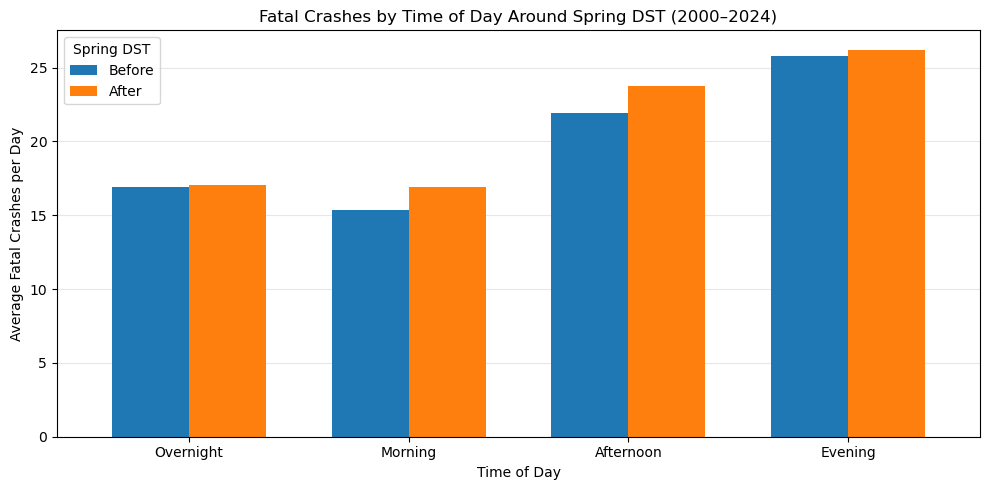

In [23]:
# Count crashes in each time-of-day category and DST period
category_counts = (
    spring.groupby(
        ["time_of_day", "dst_period"],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
    .reindex(periods)
)

# 25 years x 21 days per period
days_per_period = 25 * 21

# Convert totals to average daily crash counts
category_daily = category_counts / days_per_period

# Calculate percentage changes
category_change = (
    (category_daily["After"] / category_daily["Before"] - 1) * 100
)

# Display descriptive results
descriptive_results = pd.DataFrame({
    "Before (daily)": category_daily["Before"],
    "After (daily)": category_daily["After"],
    "Percent Change": category_change
})

display(descriptive_results.round(2))

# Create the updated figure
ax = category_daily[["Before", "After"]].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
    width=0.7
)

ax.set_title(
    "Fatal Crashes by Time of Day Around Spring DST (2000–2024)"
)
ax.set_xlabel("Time of Day")
ax.set_ylabel("Average Fatal Crashes per Day")
ax.legend(title="Spring DST")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Save for inclusion in Overleaf
plt.savefig(
    "../TODfigures/figure3_spring_dst_time_of_day.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Percentage-change graph

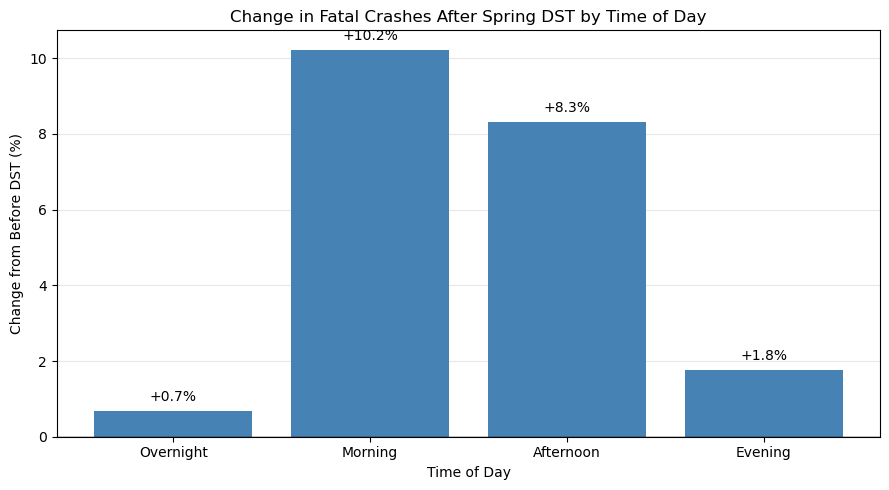

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))

colors = [
    "steelblue" if change >= 0 else "indianred"
    for change in category_change
]

bars = ax.bar(
    periods,
    category_change.values,
    color=colors
)

ax.axhline(0, color="black", linewidth=1)

for bar, value in zip(bars, category_change.values):
    ax.annotate(
        f"{value:+.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5 if value >= 0 else -5),
        textcoords="offset points",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

ax.set_title(
    "Change in Fatal Crashes After Spring DST by Time of Day"
)
ax.set_xlabel("Time of Day")
ax.set_ylabel("Change from Before DST (%)")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Outline for report for these figures

Key observations:

I. Morning crashes
- Morning crashes increased by 10.22%.
- Average daily crashes increased from 15.35 to 16.92.
- The result is consistent with the preliminary six-day finding of an 11.73% increase.
- Morning remains the largest relative increase under the expanded window.

II. Comparison with the other time periods
- Afternoon crashes increased by 8.30%, the second-largest relative change.
- Afternoon had the largest absolute increase, approximately 1.82 crashes per day.
- Overnight and evening changes were comparatively small, at 0.69% and 1.75%.
- Evening had the highest baseline crash frequency, but a much smaller relative change than morning.

III. Transition to the statistical analysis
- Differences in observed percentages do not establish statistical significance.
- Year-to-year variation, weekday effects, and seasonal trends could influence the observed patterns.
- The next step is to test the DST × time-of-day interaction in a Poisson regression.

## Poisson Regression with a DST × Time-of-Day Interaction

To test whether the association between spring DST and fatal crash
counts differs by time of day, we fit a Poisson generalized linear
model.

The response is the number of fatal crashes for each date and
time-of-day category.

The model includes:
- Post-DST indicator
- Time-of-day category
- Post-DST × time-of-day interaction
- Year fixed effects
- Day-of-week fixed effects
- Linear trend in days relative to spring DST

Standard errors are clustered by year, consistent with the group's
main regression analysis.

### Construct daily counts by time of day

We must construct four observations per day, one for each of the time-of-day categories and retain dates with zero crashes in a category.

In [14]:
# Count crashes by date and time of day
daily_counts = (
    spring.groupby(
        ["crash_date", "time_of_day"],
        observed=True
    )
    .size()
    .reset_index(name="fatal_crashes")
)

# Construct the complete calendar for all 25 years
calendar_rows = []

for _, row in dst_dates.iterrows():
    transition = row["spring_dst"]

    dates = pd.date_range(
        transition - pd.Timedelta(days=21),
        transition + pd.Timedelta(days=21)
    )

    for date in dates:
        if date != transition:
            calendar_rows.append({
                "crash_date": date,
                "year": row["year"],
                "spring_dst": transition
            })

calendar_df = pd.DataFrame(calendar_rows)

# Create one row for each date and time-of-day category
daily_data = calendar_df.merge(
    pd.DataFrame({"time_of_day": periods}),
    how="cross"
)

# Merge observed counts into the complete calendar
daily_data = daily_data.merge(
    daily_counts,
    on=["crash_date", "time_of_day"],
    how="left"
)

# Missing combinations correspond to zero observed crashes
daily_data["fatal_crashes"] = (
    daily_data["fatal_crashes"].fillna(0).astype(int)
)

# Construct regression predictors
daily_data["days_from_spring"] = (
    daily_data["crash_date"] - daily_data["spring_dst"]
).dt.days

daily_data["post_dst"] = (
    daily_data["days_from_spring"] > 0
).astype(int)

daily_data["day_of_week"] = daily_data["crash_date"].dt.dayofweek

# Fix the category order and reference level
daily_data["time_of_day"] = pd.Categorical(
    daily_data["time_of_day"],
    categories=periods,
    ordered=True)

print("Total observations:", len(daily_data))
print("Expected observations:", 25 * 42 * 4)
print("Number of years:", daily_data["year"].nunique())

assert len(daily_data) == 25 * 42 * 4
assert daily_data["fatal_crashes"].sum() == len(spring)

display(daily_data.head())

Total observations: 4200
Expected observations: 4200
Number of years: 25


,crash_date,year,spring_dst,time_of_day,fatal_crashes,days_from_spring,post_dst,day_of_week
0,2000-03-12,2000,2000-04-02,Overnight,37,-21,0,6
1,2000-03-12,2000,2000-04-02,Morning,13,-21,0,6
2,2000-03-12,2000,2000-04-02,Afternoon,21,-21,0,6
3,2000-03-12,2000,2000-04-02,Evening,20,-21,0,6
4,2000-03-13,2000,2000-04-02,Overnight,11,-20,0,0


### Fit the Poisson interaction model

In [16]:
# Fit Poisson regression with a DST x time-of-day interaction
tod_model = smf.glm(
    formula=(
        "fatal_crashes ~ post_dst * C(time_of_day) "
        "+ C(year) + C(day_of_week) + days_from_spring"
    ),
    data=daily_data,
    family=sm.families.Poisson()
).fit(
    cov_type="cluster",
    cov_kwds={"groups": daily_data["year"]}
)

print(tod_model.summary())

# Check overdispersion
dispersion = tod_model.pearson_chi2 / tod_model.df_resid

print(f"\nPearson dispersion: {dispersion:.2f}")

                 Generalized Linear Model Regression Results                  
Dep. Variable:          fatal_crashes   No. Observations:                 4200
Model:                            GLM   Df Residuals:                     4161
Model Family:                 Poisson   Df Model:                           38
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -14000.
Date:                Sun, 08 Nov 2026   Deviance:                       7937.9
Time:                        11:30:22   Pearson chi2:                 8.06e+03
No. Iterations:                     4   Pseudo R-squ. (CS):             0.7876
Covariance Type:              cluster                                         
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------


### Test the overall interaction

In [17]:
# Identify all DST x time-of-day interaction coefficients
interaction_terms = [
    name for name in tod_model.params.index
    if name.startswith("post_dst:C(time_of_day)")
]

print("Interaction terms:")
print(interaction_terms)

# Joint Wald test: all interaction coefficients equal zero
R = np.zeros((
    len(interaction_terms),
    len(tod_model.params)
))

for i, term in enumerate(interaction_terms):
    j = tod_model.params.index.get_loc(term)
    R[i, j] = 1

wald_result = tod_model.wald_test(
    R,
    scalar=True
)

print("\nOverall interaction test")
print(f"Wald chi-square: {wald_result.statistic:.3f}")
print(f"Degrees of freedom: {len(interaction_terms)}")
print(f"P-value: {wald_result.pvalue:.4f}")

Interaction terms:
['post_dst:C(time_of_day)[T.Morning]', 'post_dst:C(time_of_day)[T.Afternoon]', 'post_dst:C(time_of_day)[T.Evening]']

Overall interaction test
Wald chi-square: 29.088
Degrees of freedom: 3
P-value: 0.0000


### Estimate the adjusted change for each time period

In [18]:
# Calculate the adjusted post-DST effect for each time period
results = []

param_names = tod_model.params.index

for period in periods:

    # Construct a linear combination of regression coefficients
    contrast = np.zeros(len(param_names))

    contrast[param_names.get_loc("post_dst")] = 1

    if period != "Overnight":
        term = f"post_dst:C(time_of_day)[T.{period}]"
        contrast[param_names.get_loc(term)] = 1

    # Test the combined coefficient using clustered covariance
    test = tod_model.t_test(contrast)

    beta = float(np.asarray(test.effect).item())
    se = float(np.asarray(test.sd).item())
    p_value = float(np.asarray(test.pvalue).item())

    # Convert log-rate estimates to percentage changes
    lower = beta - 1.96 * se
    upper = beta + 1.96 * se

    results.append({
        "Time of Day": period,
        "Adjusted Change (%)": (np.exp(beta) - 1) * 100,
        "CI Lower (%)": (np.exp(lower) - 1) * 100,
        "CI Upper (%)": (np.exp(upper) - 1) * 100,
        "P-value": p_value
    })

adjusted_results = pd.DataFrame(results)

display(adjusted_results.round(3))

,Time of Day,Adjusted Change (%),CI Lower (%),CI Upper (%),P-value
0,Overnight,0.745,-2.875,4.500,0.691
1,Morning,10.286,5.393,15.407,0.000
2,Afternoon,8.365,4.817,12.033,0.000
3,Evening,1.810,-1.890,5.650,0.342


### Compare morning with the other periods

In [19]:
# Pairwise comparisons: morning versus other periods
comparisons = []

for other_period in ["Overnight", "Afternoon", "Evening"]:

    contrast = np.zeros(len(param_names))

    # Morning interaction coefficient
    morning_term = "post_dst:C(time_of_day)[T.Morning]"
    contrast[param_names.get_loc(morning_term)] = 1

    # Subtract the comparison period's interaction coefficient
    if other_period != "Overnight":
        other_term = (
            f"post_dst:C(time_of_day)[T.{other_period}]"
        )
        contrast[param_names.get_loc(other_term)] = -1

    test = tod_model.t_test(contrast)

    beta = float(np.asarray(test.effect).item())
    se = float(np.asarray(test.sd).item())
    p_value = float(np.asarray(test.pvalue).item())

    comparisons.append({
        "Comparison": f"Morning vs. {other_period}",
        "Rate Ratio": np.exp(beta),
        "CI Lower": np.exp(beta - 1.96 * se),
        "CI Upper": np.exp(beta + 1.96 * se),
        "P-value": p_value
    })

morning_comparisons = pd.DataFrame(comparisons)

display(morning_comparisons.round(4))

,Comparison,Rate Ratio,CI Lower,CI Upper,P-value
0,Morning vs. Overnight,1.0947,1.0503,1.1409,0.0000
1,Morning vs. Afternoon,1.0177,0.9761,1.0611,0.4094
2,Morning vs. Evening,1.0833,1.0371,1.1315,0.0003


### Final adjusted-effects figure

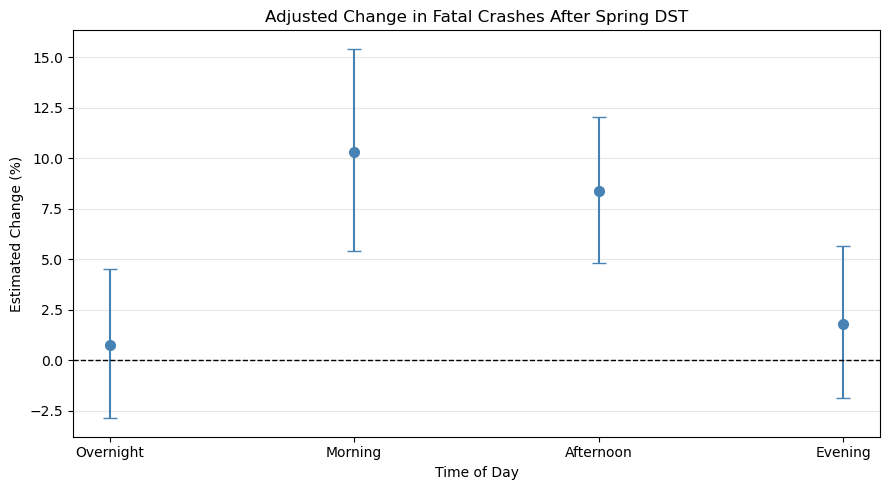

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(adjusted_results))
estimates = adjusted_results["Adjusted Change (%)"].to_numpy()

lower_errors = (
    estimates - adjusted_results["CI Lower (%)"].to_numpy()
)

upper_errors = (
    adjusted_results["CI Upper (%)"].to_numpy() - estimates
)

ax.errorbar(
    x,
    estimates,
    yerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=5,
    markersize=7,
    linewidth=1.5,
    color="steelblue"
)

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xticks(x)
ax.set_xticklabels(adjusted_results["Time of Day"])

ax.set_title(
    "Adjusted Change in Fatal Crashes After Spring DST"
)

ax.set_xlabel("Time of Day")
ax.set_ylabel("Estimated Change (%)")

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Save for inclusion in Overleaf
plt.savefig(
    "../TODfigures/spring_dst_time_of_day_adjusted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Sensitivity Analysis

In [22]:
sensitivity = []

for window in [7, 14, 21]:

    subset = daily_data[
        daily_data["days_from_spring"].between(-window, window)
    ].copy()

    model = smf.glm(
        formula=(
            "fatal_crashes ~ post_dst * C(time_of_day) "
            "+ C(year) + C(day_of_week) + days_from_spring"
        ),
        data=subset,
        family=sm.families.Poisson()
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": subset["year"]}
    )

    terms = [
        name for name in model.params.index
        if name.startswith("post_dst:C(time_of_day)")
    ]

    R = np.zeros((len(terms), len(model.params)))

    for i, term in enumerate(terms):
        R[i, model.params.index.get_loc(term)] = 1

    test = model.wald_test(R, scalar=True)

    sensitivity.append({
        "Window": f"{window} days",
        "Interaction P-value": float(test.pvalue),
        "Dispersion": model.pearson_chi2 / model.df_resid
    })

sensitivity_results = pd.DataFrame(sensitivity)

display(sensitivity_results.round(4))

,Window,Interaction P-value,Dispersion
0,7 days,0.0606,1.8713
1,14 days,0.0004,1.8737
2,21 days,0.0000,1.9369


#### Outline for the statistical analysis portion of my section

I. Poisson Regression
A. Response variable and observational units
- The response variable is the daily number of fatal crashes within each time-of-day category.
- The model contains 4,200 observations, corresponding to 25 years × 42 days × 4 categories.
- Each date contributes four observations: overnight, morning, afternoon, and evening.
- Transition Sundays are excluded.
B. Model specification
- Fit a Poisson generalized linear model with a log link.
- Include the post-DST indicator, time-of-day categories, and their interaction.
- Adjust for year fixed effects, weekday fixed effects, and a linear trend in days relative to spring DST.
- Cluster standard errors by year, consistent with the group's primary analysis.
C. Mathematical representation

You can include the following equation in your report:
\[
Y_{ydh}\sim\operatorname{Poisson}(\mu_{ydh})
\]

\[
\begin{aligned}
\log(\mu_{ydh})={}&\beta_0+\beta_1\mathrm{PostDST}_{yd}\\
&+\alpha_h+\delta_h\mathrm{PostDST}_{yd}\\
&+\gamma_y+\eta_{w(d)}+\beta_2t_{yd}.
\end{aligned}
\]

Here, \(y\) denotes year, \(d\) denotes date, and \(h\) denotes time of day. The \(\delta_h\) terms represent the interactions, with overnight as the reference category.

D. Interpretation of the interaction

The interaction allows the proportional change in expected fatal crash counts after DST to vary across the four time periods.

The null hypothesis is that all three nonreference interaction coefficients equal zero.

II. Interaction test
A. Statistical hypotheses
\[
H_0:\delta_{\mathrm{Morning}}
=\delta_{\mathrm{Afternoon}}
=\delta_{\mathrm{Evening}}=0
\]

\[
H_A:\text{At least one interaction coefficient is nonzero.}
\]

B. Results
- Wald chi-square statistic: 29.088.
- Degrees of freedom: 3.
- p-value: less than 0.001.
- Reject the null hypothesis at the 5% significance level.
C. Interpretation

There is statistically significant evidence that the association between spring DST and fatal crash counts varies by time of day.

This is the primary result supporting your additional research question.

III. 

### Fit the model using HC3 robust standard errors

In [25]:
# Refit the same Poisson model using HC3 robust standard errors
tod_model_hc3 = smf.glm(
    formula=(
        "fatal_crashes ~ post_dst * C(time_of_day) "
        "+ C(year) + C(day_of_week) + days_from_spring"
    ),
    data=daily_data,
    family=sm.families.Poisson()
).fit(
    cov_type="HC3"
)

print(tod_model_hc3.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:          fatal_crashes   No. Observations:                 4200
Model:                            GLM   Df Residuals:                     4161
Model Family:                 Poisson   Df Model:                           38
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -14000.
Date:                Sun, 08 Nov 2026   Deviance:                       7937.9
Time:                        13:11:20   Pearson chi2:                 8.06e+03
No. Iterations:                     4   Pseudo R-squ. (CS):             0.7876
Covariance Type:                  HC3                                         
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------


### Compare the overall interaction tests

In [26]:
# Identify the DST x time-of-day interaction coefficients
interaction_terms = [
    name for name in tod_model.params.index
    if name.startswith("post_dst:C(time_of_day)")
]

# Construct the joint hypothesis matrix
R = np.zeros((
    len(interaction_terms),
    len(tod_model.params)
))

for i, term in enumerate(interaction_terms):
    j = tod_model.params.index.get_loc(term)
    R[i, j] = 1

# Wald tests using each covariance estimator
cluster_test = tod_model.wald_test(R, scalar=True)
hc3_test = tod_model_hc3.wald_test(R, scalar=True)

comparison = pd.DataFrame({
    "Variance Estimator": ["Clustered by Year", "HC3 Robust"],
    "Wald Chi-Square": [
        float(cluster_test.statistic),
        float(hc3_test.statistic)
    ],
    "P-value": [
        float(cluster_test.pvalue),
        float(hc3_test.pvalue)
    ]
})

display(comparison.round(5))

,Variance Estimator,Wald Chi-Square,P-value
0,Clustered by Year,29.08814,0.00000
1,HC3 Robust,16.46856,0.00091


### Compare the interaction coefficients and standard errors

In [27]:
# Compare coefficient uncertainty across covariance estimators
rows = []

for term in interaction_terms:
    rows.append({
        "Interaction": term,
        "Coefficient": tod_model.params[term],
        "Clustered SE": tod_model.bse[term],
        "HC3 SE": tod_model_hc3.bse[term],
        "Clustered P-value": tod_model.pvalues[term],
        "HC3 P-value": tod_model_hc3.pvalues[term]
    })

se_comparison = pd.DataFrame(rows)

display(se_comparison.round(4))

,Interaction,Coefficient,Clustered SE,HC3 SE,Clustered P-value,HC3 P-value
0,post_dst:C(time_of_day)[T.Morning],0.0905,0.0211,0.0339,0.0000,0.0076
1,post_dst:C(time_of_day)[T.Afternoon],0.0729,0.0209,0.0310,0.0005,0.0188
2,post_dst:C(time_of_day)[T.Evening],0.0105,0.0216,0.0308,0.6256,0.7329
